In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 20)

print("Ready.")


Ready.


In [2]:
df = pd.read_csv("country_wise_latest.csv")
print("Shape:", df.shape)
df.head()


Shape: (187, 15)


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [3]:
df.dtypes


Country/Region                str
Confirmed                   int64
Deaths                      int64
Recovered                   int64
Active                      int64
New cases                   int64
New deaths                  int64
New recovered               int64
Deaths / 100 Cases        float64
Recovered / 100 Cases     float64
Deaths / 100 Recovered    float64
Confirmed last week         int64
1 week change               int64
1 week % increase         float64
WHO Region                    str
dtype: object

In [4]:
df.isna().sum()


Country/Region            0
Confirmed                 0
Deaths                    0
Recovered                 0
Active                    0
New cases                 0
New deaths                0
New recovered             0
Deaths / 100 Cases        0
Recovered / 100 Cases     0
Deaths / 100 Recovered    0
Confirmed last week       0
1 week change             0
1 week % increase         0
WHO Region                0
dtype: int64

In [5]:
print("Number of countries:", df["Country/Region"].nunique())
print("Number of duplicate rows:", df.duplicated().sum())
df["WHO Region"].value_counts()


Number of countries: 187
Number of duplicate rows: 0


WHO Region
Europe                   56
Africa                   48
Americas                 35
Eastern Mediterranean    22
Western Pacific          16
South-East Asia          10
Name: count, dtype: int64

In [6]:
df_clean = df.rename(columns={
    "Country/Region": "country",
    "Confirmed": "confirmed",
    "Deaths": "deaths",
    "Recovered": "recovered",
    "Active": "active",
    "New cases": "new_cases",
    "New deaths": "new_deaths",
    "New recovered": "new_recovered",
    "Deaths / 100 Cases": "death_rate",
    "Recovered / 100 Cases": "recovery_rate",
    "Deaths / 100 Recovered": "death_per_100_recovered",
    "Confirmed last week": "confirmed_last_week",
    "1 week change": "week_change",
    "1 week % increase": "week_pct_increase",
    "WHO Region": "who_region",
}).copy()

# Tidy up text columns
df_clean["country"] = df_clean["country"].str.strip()
df_clean["who_region"] = df_clean["who_region"].str.strip()

print("Clean shape:", df_clean.shape)
df_clean.dtypes


Clean shape: (187, 15)


country                        str
confirmed                    int64
deaths                       int64
recovered                    int64
active                       int64
new_cases                    int64
new_deaths                   int64
new_recovered                int64
death_rate                 float64
recovery_rate              float64
death_per_100_recovered    float64
confirmed_last_week          int64
week_change                  int64
week_pct_increase          float64
who_region                     str
dtype: object

In [7]:
df_clean.isna().sum().sum()   # should be 0 -- fully clean


np.int64(0)

In [8]:
region_summary = df_clean.groupby("who_region", as_index=False)[
    ["confirmed", "deaths", "recovered", "active"]
].sum()
region_summary["death_rate"] = (region_summary["deaths"] / region_summary["confirmed"] * 100).round(2)
region_summary["recovery_rate"] = (region_summary["recovered"] / region_summary["confirmed"] * 100).round(2)
region_summary = region_summary.sort_values("confirmed", ascending=False).reset_index(drop=True)
region_summary


,who_region,confirmed,deaths,recovered,active,death_rate,recovery_rate
0,Americas,8839286,342732,4468616,4027938,3.88,50.55
1,Europe,3299523,211144,1993723,1094656,6.40,60.42
2,South-East Asia,1835297,41349,1156933,637015,2.25,63.04
3,Eastern Mediterranean,1490744,38339,1201400,251005,2.57,80.59
4,Africa,723207,12223,440645,270339,1.69,60.93
5,Western Pacific,292428,8249,206770,77409,2.82,70.71


In [9]:
print(f"Total countries covered : {df_clean.shape[0]}")
print(f"Total confirmed (global)  : {df_clean['confirmed'].sum():,}")
print(f"Total deaths (global)     : {df_clean['deaths'].sum():,}")
print(f"Total recovered (global)  : {df_clean['recovered'].sum():,}")
print(f"Global death rate         : {(df_clean['deaths'].sum() / df_clean['confirmed'].sum() * 100):.2f}%")
print(f"Global recovery rate      : {(df_clean['recovered'].sum() / df_clean['confirmed'].sum() * 100):.2f}%")


Total countries covered : 187
Total confirmed (global)  : 16,480,485
Total deaths (global)     : 654,036
Total recovered (global)  : 9,468,087
Global death rate         : 3.97%
Global recovery rate      : 57.45%


In [10]:
top10 = df_clean.sort_values("confirmed", ascending=False).head(10).reset_index(drop=True)
top10[["country", "confirmed", "deaths", "recovered", "death_rate", "recovery_rate", "who_region"]]


,country,confirmed,deaths,recovered,death_rate,recovery_rate,who_region
0,US,4290259,148011,1325804,3.45,30.90,Americas
1,Brazil,2442375,87618,1846641,3.59,75.61,Americas
2,India,1480073,33408,951166,2.26,64.26,South-East Asia
3,Russia,816680,13334,602249,1.63,73.74,Europe
4,South Africa,452529,7067,274925,1.56,60.75,Africa
5,Mexico,395489,44022,303810,11.13,76.82,Americas
6,Peru,389717,18418,272547,4.73,69.93,Americas
7,Chile,347923,9187,319954,2.64,91.96,Americas
8,United Kingdom,301708,45844,1437,15.19,0.48,Europe
9,Iran,293606,15912,255144,5.42,86.90,Eastern Mediterranean


In [11]:
df_clean["size_bucket"] = pd.cut(
    df_clean["confirmed"],
    bins=[-1, 1000, 10000, 100000, float("inf")],
    labels=["<1k", "1k-10k", "10k-100k", "100k+"],
)
region_bucket_pivot = df_clean.pivot_table(
    values="country", index="who_region", columns="size_bucket",
    aggfunc="count", fill_value=0, observed=True
)
region_bucket_pivot


size_bucket,<1k,1k-10k,10k-100k,100k+
who_region,,,,
Africa,14,26,7,1
Americas,12,6,9,8
Eastern Mediterranean,1,7,9,5
Europe,7,18,24,7
South-East Asia,3,3,1,3
Western Pacific,8,2,6,0


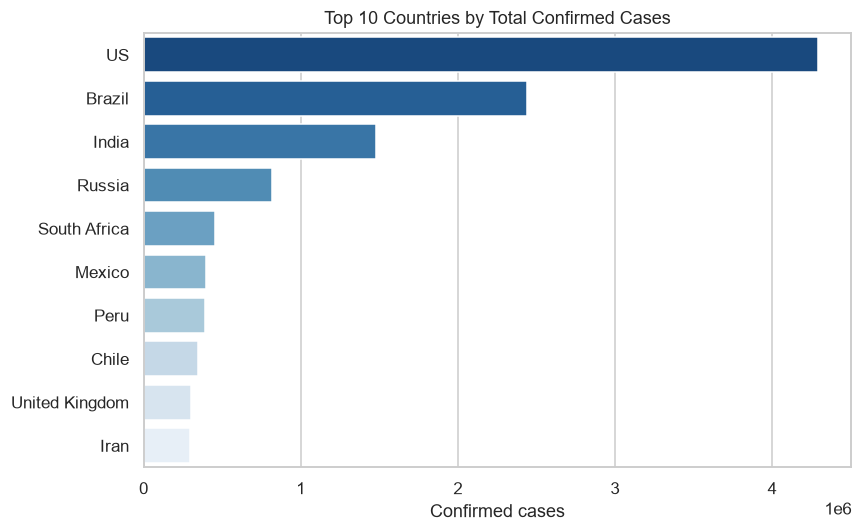

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top10, y="country", x="confirmed", hue="country", palette="Blues_r", legend=False, ax=ax)
ax.set_title("Top 10 Countries by Total Confirmed Cases")
ax.set_xlabel("Confirmed cases"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

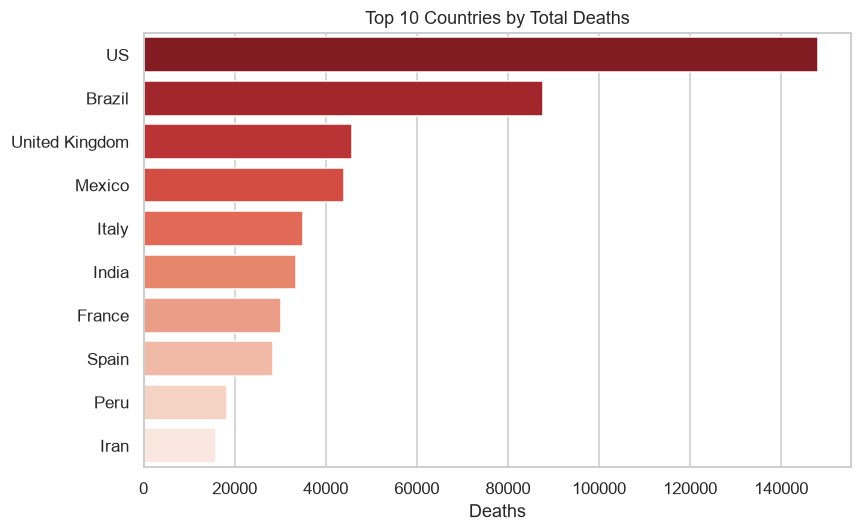

In [13]:
top10_deaths = df_clean.sort_values("deaths", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top10_deaths, y="country", x="deaths", hue="country", palette="Reds_r", legend=False, ax=ax)
ax.set_title("Top 10 Countries by Total Deaths")
ax.set_xlabel("Deaths"); ax.set_ylabel("")
plt.tight_layout()
plt.show()


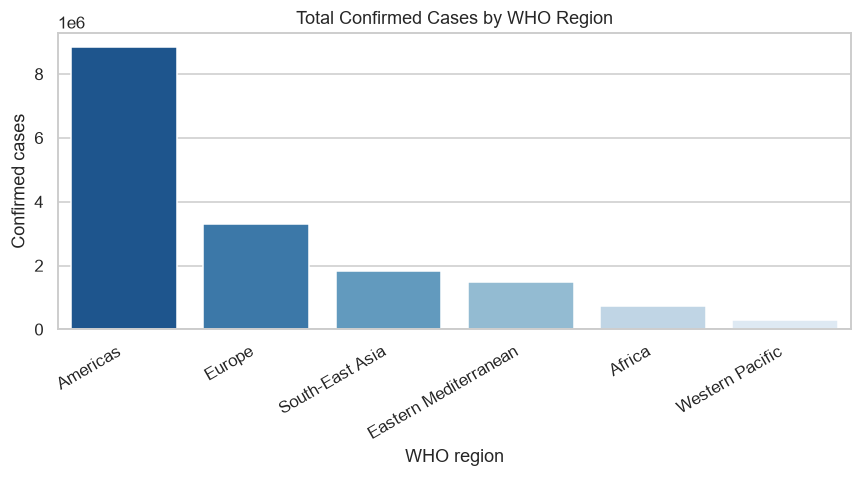

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=region_summary, x="who_region", y="confirmed", hue="who_region", palette="Blues_r", legend=False, ax=ax)
ax.set_title("Total Confirmed Cases by WHO Region")
ax.set_xlabel("WHO region"); ax.set_ylabel("Confirmed cases")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

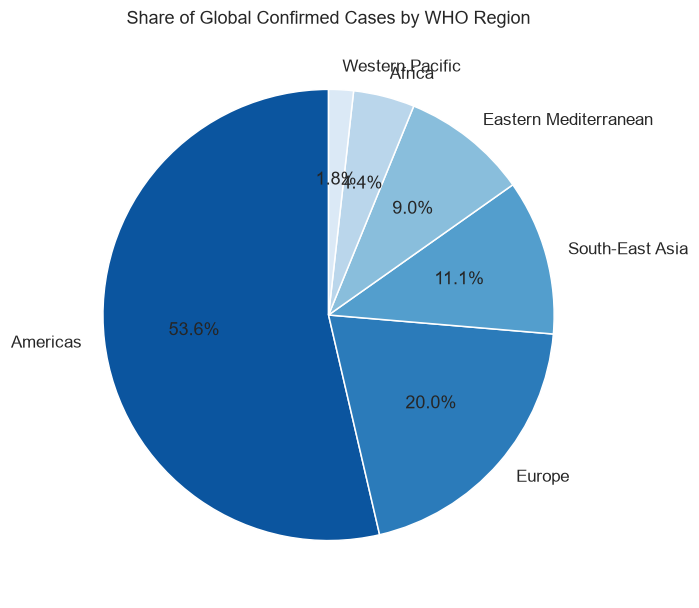

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(region_summary["confirmed"], labels=region_summary["who_region"], autopct="%1.1f%%",
       startangle=90, colors=sns.color_palette("Blues_r", len(region_summary)))
ax.set_title("Share of Global Confirmed Cases by WHO Region")
plt.tight_layout()
plt.show()


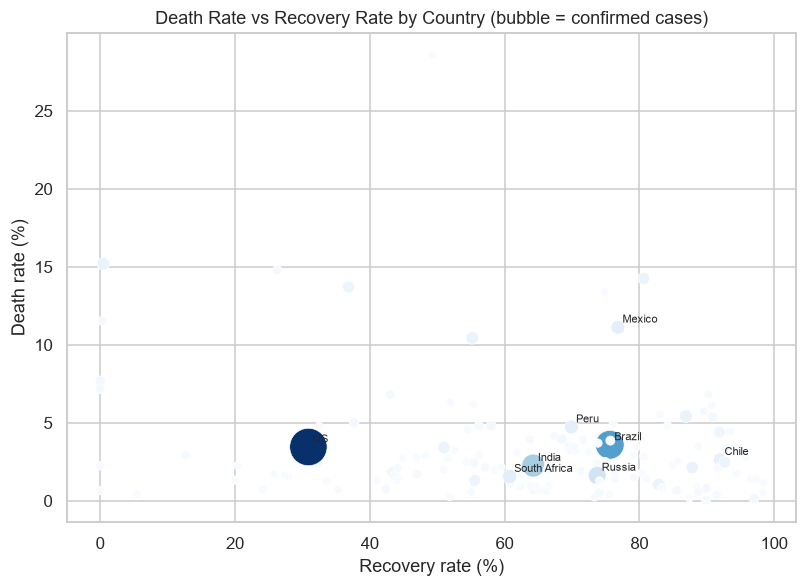

In [16]:
sizeable = df_clean[df_clean["confirmed"] >= 1000]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=sizeable, x="recovery_rate", y="death_rate", size="confirmed",
                 sizes=(30, 600), hue="confirmed", palette="Blues", legend=False, ax=ax)
for _, r in sizeable.nlargest(8, "confirmed").iterrows():
    ax.annotate(r["country"], (r["recovery_rate"], r["death_rate"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_title("Death Rate vs Recovery Rate by Country (bubble = confirmed cases)")
ax.set_xlabel("Recovery rate (%)"); ax.set_ylabel("Death rate (%)")
plt.tight_layout()
plt.show()


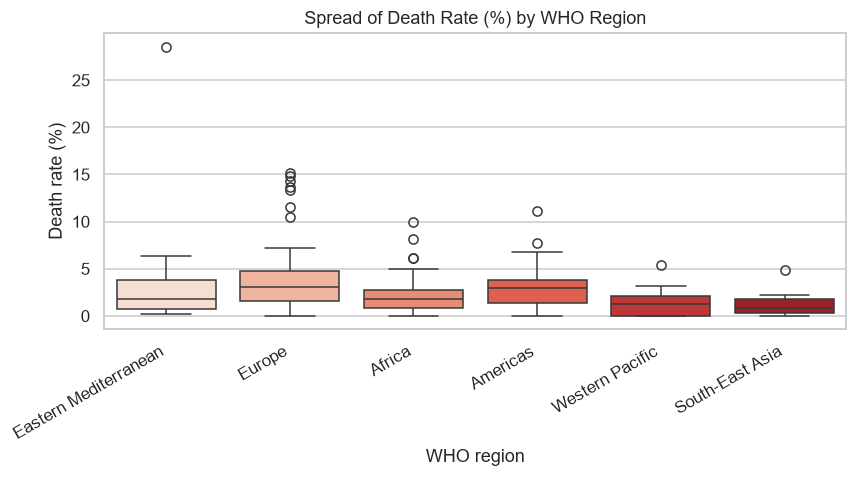

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_clean, x="who_region", y="death_rate", hue="who_region", palette="Reds", legend=False, ax=ax)
ax.set_title("Spread of Death Rate (%) by WHO Region")
ax.set_xlabel("WHO region"); ax.set_ylabel("Death rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

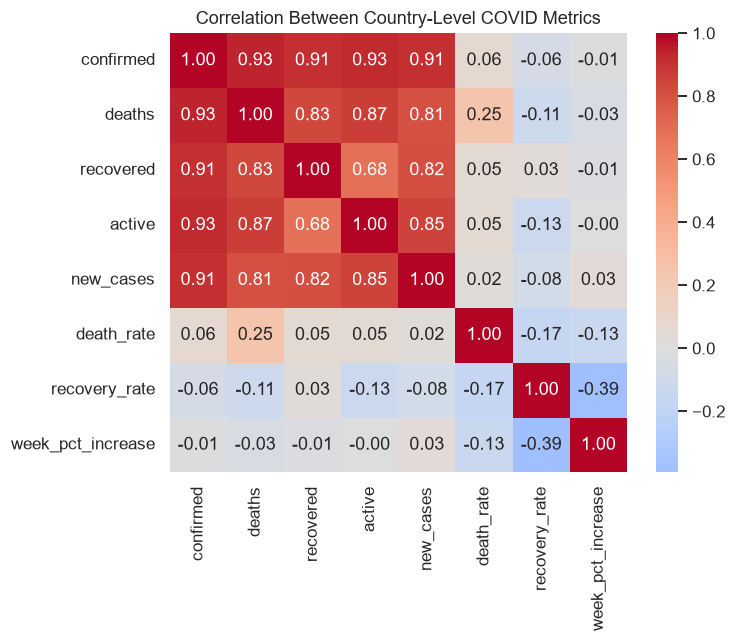

In [18]:
corr_cols = ["confirmed", "deaths", "recovered", "active", "new_cases",
             "death_rate", "recovery_rate", "week_pct_increase"]
corr = df_clean[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Country-Level COVID Metrics")
plt.tight_layout()
plt.show()

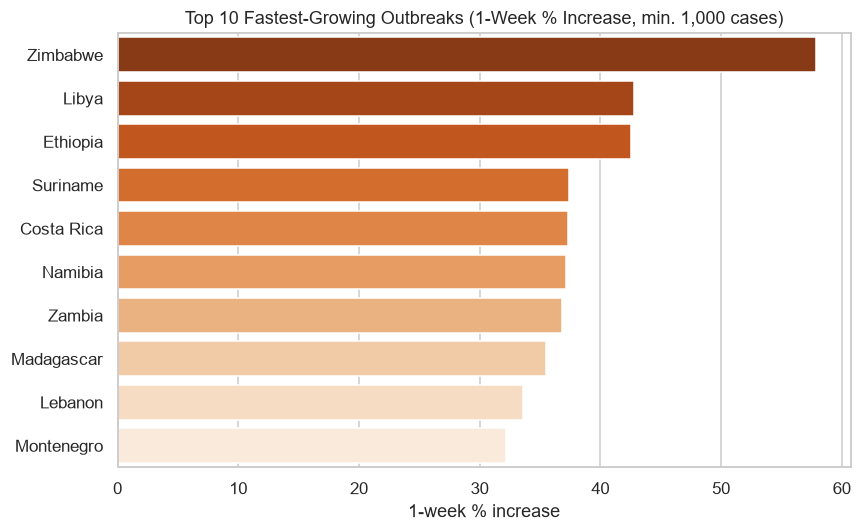

In [19]:
fastest = df_clean[df_clean["confirmed"] >= 1000].sort_values("week_pct_increase", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=fastest, y="country", x="week_pct_increase", hue="country", palette="Oranges_r", legend=False, ax=ax)
ax.set_title("Top 10 Fastest-Growing Outbreaks (1-Week % Increase, min. 1,000 cases)")
ax.set_xlabel("1-week % increase"); ax.set_ylabel("")
plt.tight_layout()
plt.show()


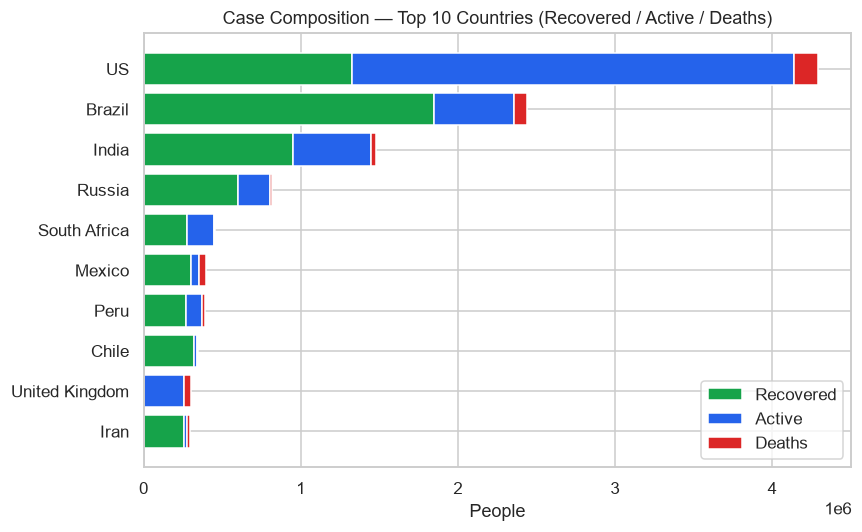

In [20]:
top10_sorted = top10.sort_values("confirmed")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10_sorted["country"], top10_sorted["recovered"], color="#16a34a", label="Recovered")
ax.barh(top10_sorted["country"], top10_sorted["active"], left=top10_sorted["recovered"], color="#2563eb", label="Active")
ax.barh(top10_sorted["country"], top10_sorted["deaths"],
        left=top10_sorted["recovered"] + top10_sorted["active"], color="#dc2626", label="Deaths")
ax.set_title("Case Composition — Top 10 Countries (Recovered / Active / Deaths)")
ax.set_xlabel("People"); ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()


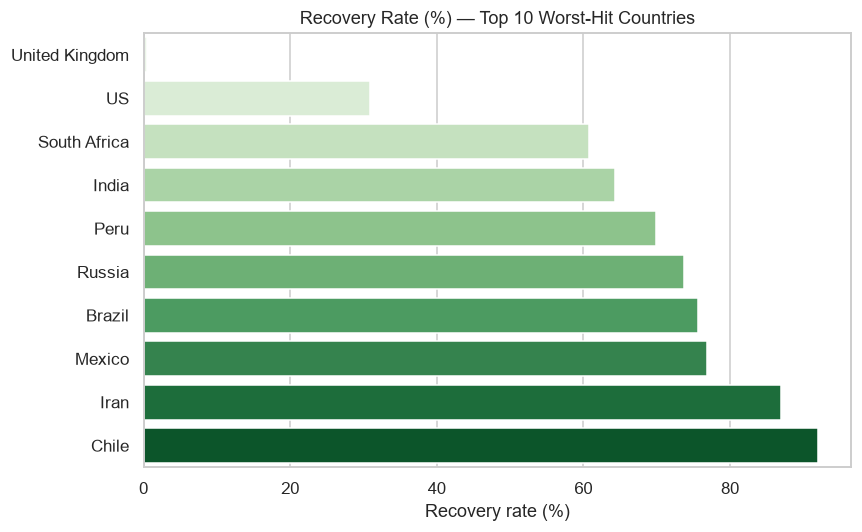

In [21]:
top10_by_recovery = top10.sort_values("recovery_rate")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top10_by_recovery, y="country", x="recovery_rate", hue="country", palette="Greens", legend=False, ax=ax)
ax.set_title("Recovery Rate (%) — Top 10 Worst-Hit Countries")
ax.set_xlabel("Recovery rate (%)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()


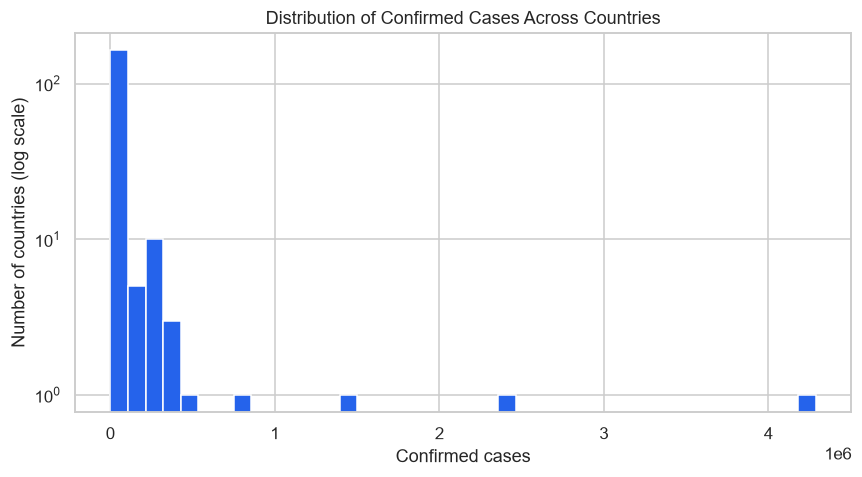

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_clean["confirmed"], bins=40, color="#2563eb", edgecolor="white")
ax.set_yscale("log")
ax.set_title("Distribution of Confirmed Cases Across Countries")
ax.set_xlabel("Confirmed cases"); ax.set_ylabel("Number of countries (log scale)")
plt.tight_layout()
plt.show()


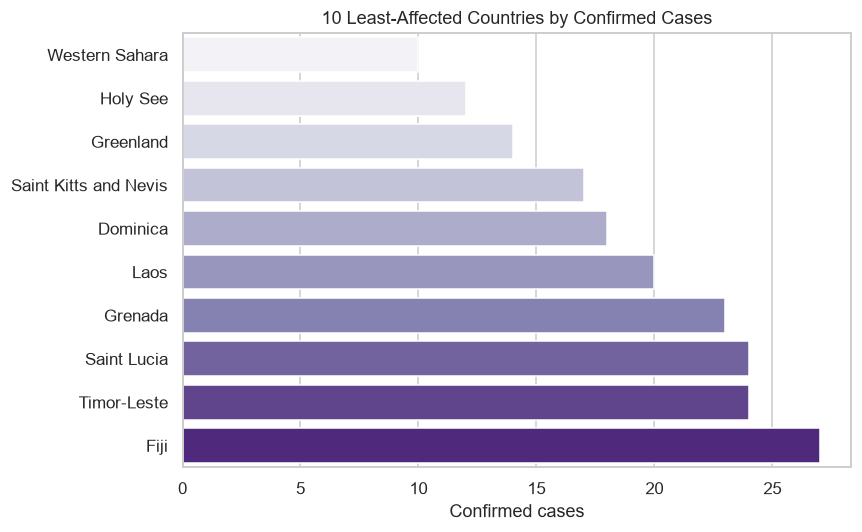

In [23]:
bottom10 = df_clean[df_clean["confirmed"] >= 10].nsmallest(10, "confirmed")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=bottom10, y="country", x="confirmed", hue="country", palette="Purples", legend=False, ax=ax)
ax.set_title("10 Least-Affected Countries by Confirmed Cases")
ax.set_xlabel("Confirmed cases"); ax.set_ylabel("")
plt.tight_layout()
plt.show()


In [24]:
df_clean.to_csv("cleaned_country_wise_covid.csv", index=False)
print("Saved cleaned_country_wise_covid.csv —", df_clean.shape[0], "rows.")


Saved cleaned_country_wise_covid.csv — 187 rows.
